# Задание 4.12**
## Встреча $n$ лиц с разным временем ожидания

### Условие:
Пусть $n$ лиц имеют время ожидания $w_1,\dots,w_n$ (в долях общего интервала). Моменты прихода — независимые равномерные на $[0,1]$. Докажите формулы вероятности встречи: а) $n=2$: $P_2=1-\frac{(1-w_1)^2}{2}-\frac{(1-w_2)^2}{2}$; б) $n=3$ (при $w_1\le w_2\le w_3$): $P_3=w_1w_2+w_1w_3+w_2w_3-\frac12(w_1w_2^2+w_1w_3^2+w_2w_3^2)-\frac13w_1^3-\frac16w_2^3$; в) $n=3$, $w=(\frac14,\frac13,\frac12)$: $P_3=\frac{1435}{5184}\approx0{,}27681$; г) $n=4$ (формула из листка).

### Общая формула (ключ к доказательству):
Лицо $i$ присутствует в течение $[t_i,\,t_i+w_i]$. Все $n$ лиц встретятся $\iff$ в момент $M=\max_jt_j$ (когда приходит последний) все присутствуют: $t_i\le M\le t_i+w_i$ для всех $i$, т. е.
$$\text{встреча}\iff M-t_i\le w_i\quad\forall i .$$
Пусть последним приходит лицо $k$ ($t_k=M=t$). Каждый другой человек $i$ должен прийти в $[t-w_i,t]\cap[0,1]$, длина $\min(w_i,t)$, т. е. с вероятностью $\min(w_i,t)$. Суммируя по $k$ (события «последним пришёл $k$» несовместны):
$$\boxed{\ P_n=\sum_{k=1}^n\int_0^1\prod_{i\ne k}\min(w_i,t)\,dt\ }$$
Для равных $w_i=q$: $P_n=n\bigl[\int_0^q t^{n-1}dt+q^{n-1}(1-q)\bigr]=nq^{n-1}-(n-1)q^n$ — формула задачи 4.11 ✓.

### Вычисление интегралов (пусть $a\le b\le c\le1$):
Разбиваем $[0,1]$ точками $a,b,c$: на $[0,a]$ все $\min=t$; на $[a,b]$ множитель $a$ уже «насытился» и т. д.
$$I(a,b)=\int_0^1\min(a,t)\min(b,t)dt=\int_0^at^2dt+\int_a^b at\,dt+\int_b^1ab\,dt=ab-\frac{ab^2}{2}-\frac{a^3}{6},$$
$$J(a,b,c)=\int_0^1\min(a,t)\min(b,t)\min(c,t)dt=abc-\frac{abc^2}{2}-\frac{ab^3}{6}-\frac{a^4}{12}.$$
**а) $n=2$:** $P_2=\int_0^1\min(w_2,t)dt+\int_0^1\min(w_1,t)dt=\bigl(w_2-\frac{w_2^2}2\bigr)+\bigl(w_1-\frac{w_1^2}2\bigr)=1-\frac{(1-w_1)^2}2-\frac{(1-w_2)^2}2$ ✓.

**б) $n=3$** ($w_1\le w_2\le w_3$): $P_3=I(w_2,w_3)+I(w_1,w_3)+I(w_1,w_2)$. Складывая, получаем ровно формулу б): слагаемые $-\frac{a^3}6$ дают $-\frac{w_2^3}6-\frac{w_1^3}6-\frac{w_1^3}6=-\frac{w_1^3}3-\frac{w_2^3}6$.

**в)** Подстановка $w=(\frac14,\frac13,\frac12)$ даёт $\dfrac{1435}{5184}$ (точная арифметика в коде).

**г) $n=4$** ($w_1\le\dots\le w_4$): $P_4=J(w_2,w_3,w_4)+J(w_1,w_3,w_4)+J(w_1,w_2,w_4)+J(w_1,w_2,w_3)$ — раскрывая, получаем формулу г) из листка (символьная проверка ниже).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from fractions import Fraction
from math import comb

rng = np.random.default_rng(2024)      # генератор псевдослучайных чисел; фиксированное «зерно» -> результаты воспроизводимы

def running_frequency(hits):
    # Относительная частота p̂_N = N(A)/N для N = 1, 2, ..., len(hits).
    # hits[i] = 1 (True), если в (i+1)-й реализации опыта событие A произошло, иначе 0.
    hits = np.asarray(hits, dtype=float)
    return np.cumsum(hits)/np.arange(1, len(hits) + 1)

def plot_frequency(ax, hits, p_exact, title, label=r'$\hat p_N(A)=N(A)/N$'):
    # График зависимости p̂(A) от числа реализаций N (статистическая устойчивость частоты):
    # синяя линия — относительная частота, красная — точная вероятность,
    # зелёные пунктиры — «коридор» P ± 3·sqrt(P(1−P)/N), в который частота попадает почти всегда.
    n = np.arange(1, len(hits) + 1)
    ph = np.cumsum(hits)/n
    sig = 3*np.sqrt(p_exact*(1 - p_exact)/n)
    ax.plot(n, ph, 'b-', lw=1, label=label)
    ax.axhline(p_exact, color='r', lw=1.5, label=f'P = {p_exact:.6f}')
    ax.plot(n, p_exact + sig, 'g--', lw=0.8, label=r'$P\pm3\sqrt{P(1-P)/N}$'); ax.plot(n, p_exact - sig, 'g--', lw=0.8)
    s = max(10, len(n)//50)                           # первые 2 % точек очень шумные; масштаб по y выбираем по остальным
    lo = min(ph[s:].min(), (p_exact - sig)[s:].min()); hi = max(ph[s:].max(), (p_exact + sig)[s:].max())
    pad = 0.1*(hi - lo); ax.set_ylim(lo - pad, hi + pad)
    ax.set_xlim(0, len(hits)); ax.grid(alpha=0.3); ax.set_xlabel('число реализаций опыта N'); ax.set_ylabel('относительная частота')
    ax.set_title(title, fontsize=10); ax.legend(fontsize=7.5, loc='upper right')

def plot_conditional(ax, hits_AB, hits_B, p_exact, title):
    # График условной частоты p̂(A|B) = N(A∩B)/N(B) в зависимости от общего числа реализаций N
    n = np.arange(1, len(hits_B) + 1); cB = np.cumsum(hits_B); cAB = np.cumsum(hits_AB)
    ph = np.where(cB > 0, cAB/np.maximum(cB, 1), np.nan)
    ax.plot(n, ph, 'b-', lw=1, label=r'$\hat p(A|B)=N(A\cap B)/N(B)$'); ax.axhline(p_exact, color='r', lw=1.5, label=f'значение {p_exact:.5f}')
    s = max(10, len(n)//20); v = ph[s:][~np.isnan(ph[s:])]; lo, hi = min(v.min(), p_exact), max(v.max(), p_exact); pad = 0.15*(hi - lo + 1e-9)
    ax.set_ylim(lo - pad, hi + pad); ax.set_xlim(0, len(hits_B)); ax.grid(alpha=0.3)
    ax.set_xlabel('число реализаций опыта N'); ax.set_ylabel('условная частота'); ax.set_title(title, fontsize=10); ax.legend(fontsize=7.5, loc='upper right')

def table(hits, p_exact, Ns=(100, 1000, 10_000, 100_000, 1_000_000)):
    # Печатает оценки p̂ при разных N, отклонение от точного значения и границу 3σ
    hits = np.asarray(hits, dtype=float)
    print('       N        p̂(N)        |p̂ − P|      3σ_N')
    for N in Ns:
        if N <= len(hits):
            ph = hits[:N].mean(); print(f'{N:9d}   {ph:.7f}   {abs(ph - p_exact):.2e}   {3*np.sqrt(p_exact*(1 - p_exact)/N):.2e}')

### Точное вычисление общей формулы (дроби) и символьная проверка формул а), б), г) (`sympy`)

In [2]:
import sympy as sp

def integral_min_product(ws):
    # ∫_0^1 Π min(w_i, t) dt для ВОЗРАСТАЮЩЕГО списка ws (числа или символы) — точно.
    # На отрезке между соседними точками разбиения [0, w_(1), ..., w_(m), 1] множители с w_i ≤ t равны w_i, остальные равны t.
    t = sp.symbols('t'); pts = [sp.Integer(0)] + list(ws) + [sp.Integer(1)]; total = 0
    for j in range(len(ws) + 1):
        integrand = sp.Mul(*ws[:j])*t**(len(ws) - j)
        total += sp.integrate(integrand, (t, pts[j], pts[j + 1]))
    return sp.expand(total)

def P_exact(ws):
    # P_n = Σ_k ∫ Π_{i≠k} min(w_i, t) dt  (ws — любой порядок, сортируем внутри)
    ws = sorted(ws); return sp.nsimplify(sum(integral_min_product(ws[:k] + ws[k + 1:]) for k in range(len(ws))))

w1, w2, w3, w4 = sp.symbols('w1 w2 w3 w4', positive=True)         # предполагаем порядок w1 ≤ w2 ≤ w3 ≤ w4 ≤ 1
# а) n = 2
sym2 = integral_min_product([w2]) + integral_min_product([w1])         # k = 1 (последний пришёл первый) и k = 2
sheet2 = 1 - (1 - w1)**2/2 - (1 - w2)**2/2
print('а) разность с формулой листка:', sp.simplify(sym2 - sheet2))
# б) n = 3
sym3 = integral_min_product([w2, w3]) + integral_min_product([w1, w3]) + integral_min_product([w1, w2])
sheet3 = w1*w2 + w1*w3 + w2*w3 - (w1*w2**2 + w1*w3**2 + w2*w3**2)/2 - w1**3/3 - w2**3/6
print('б) разность с формулой листка:', sp.simplify(sym3 - sheet3))
# г) n = 4
sym4 = (integral_min_product([w2, w3, w4]) + integral_min_product([w1, w3, w4]) + integral_min_product([w1, w2, w4]) + integral_min_product([w1, w2, w3]))
sheet4 = (w1*w2*w3 + w1*w2*w4 + w1*w3*w4 + w2*w3*w4 - w4**2/2*(w1*w2 + w1*w3 + w2*w3) - w3**3/6*(w1 + w2)
          - w1*w2*w3**2/2 - w1*w2**3/3 - w1**4/4 - w2**4/12)
print('г) разность с формулой листка:', sp.simplify(sym4 - sheet4))
# в) числовой пример
P_c = P_exact([sp.Rational(1, 4), sp.Rational(1, 3), sp.Rational(1, 2)])
print('в) P3 =', P_c, '≈', float(P_c), '   (в листке 1435/5184 =', float(sp.Rational(1435, 5184)), ')')

а) разность с формулой листка: 0
б) разность с формулой листка: 0
г) разность с формулой листка: 0
в) P3 = 1435/5184 ≈ 0.2768132716049383    (в листке 1435/5184 = 0.2768132716049383 )


### Моделирование: $P_n=\mathbb P(\forall i:\ M-t_i\le w_i)$

In [3]:
def simulate(ws, N):
    ws = np.array(ws, dtype=float); t = rng.random((N, len(ws)))
    return ((t.max(axis=1)[:, None] - t) <= ws).all(axis=1)          # все присутствуют в момент прихода последнего

cases = {'а) n=2, w=(0.2, 0.3)': [0.2, 0.3], 'в) n=3, w=(1/4, 1/3, 1/2)': [1/4, 1/3, 1/2],
         'г) n=4, w=(0.1, 0.2, 0.3, 0.5)': [0.1, 0.2, 0.3, 0.5], 'n=5, w=(0.2,0.3,0.4,0.5,0.6)': [0.2, 0.3, 0.4, 0.5, 0.6]}
N = 1_000_000; hits = {}
print(f'{"случай":34s}  точно (дробь)        точно       оценка p̂ (N = 10^6)')
for name, ws in cases.items():
    P = P_exact([sp.nsimplify(w) for w in ws]); hits[name] = simulate(ws, N)
    print(f'{name:34s}  {str(P):18s}  {float(P):.6f}    {hits[name].mean():.6f}')

случай                              точно (дробь)        точно       оценка p̂ (N = 10^6)
а) n=2, w=(0.2, 0.3)                87/200              0.435000    0.435827
в) n=3, w=(1/4, 1/3, 1/2)           1435/5184           0.276813    0.276767
г) n=4, w=(0.1, 0.2, 0.3, 0.5)      1783/40000          0.044575    0.044759
n=5, w=(0.2,0.3,0.4,0.5,0.6)        391957/6000000      0.065326    0.065345


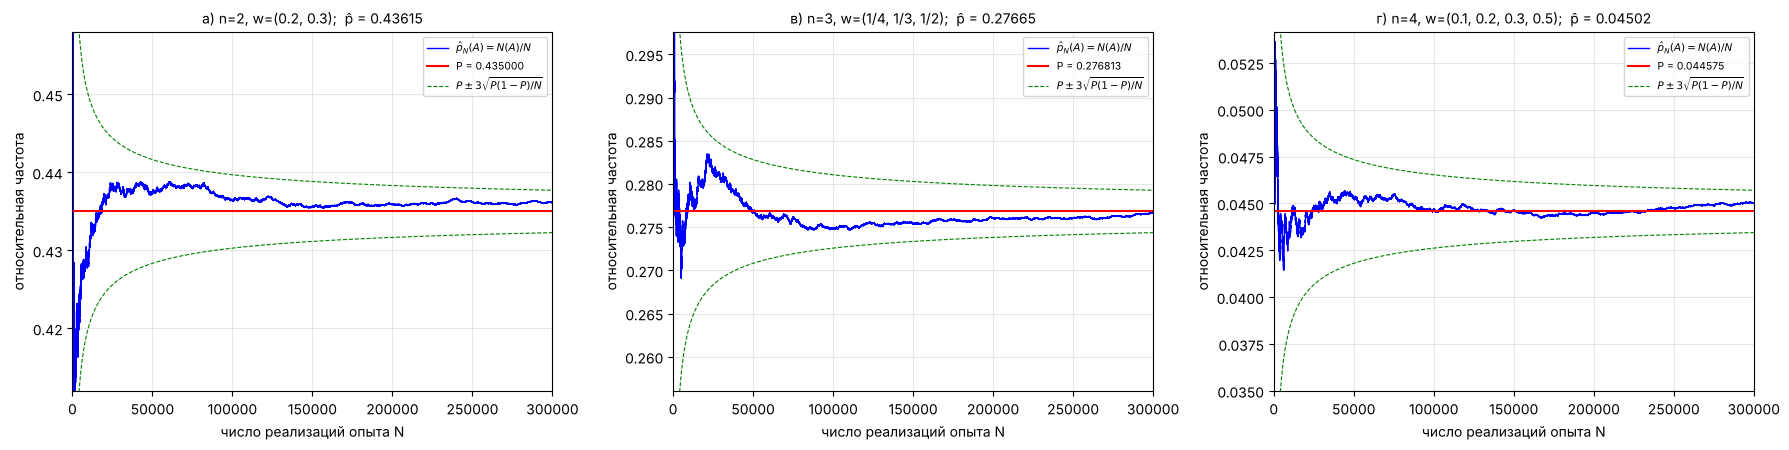

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(18, 4.6))
for ax, name in zip(axs, list(cases)[:3]):
    P = float(P_exact([sp.nsimplify(w) for w in cases[name]])); plot_frequency(ax, hits[name][:300_000], P, name + f';  p̂ = {hits[name][:300_000].mean():.5f}')
plt.tight_layout(); plt.savefig('task_4_12.png', dpi=130, bbox_inches='tight'); plt.show()

### Ответ:
Общая формула: $P_n=\sum_k\int_0^1\prod_{i\ne k}\min(w_i,t)\,dt$. Из неё (при $w_1\le w_2\le\dots$) выводятся формулы а), б), г) из листка (символьная проверка: разности равны 0); в) $P_3=\dfrac{1435}{5184}\approx0{,}27681$; при равных $w_i=q$ получается $nq^{n-1}-(n-1)q^n$ (задача 4.11).